## Лабораторная работа №2 "Разработка и сравнение алгоритмов персонализированных рекомендаций"

**ФИО:** Рыжов Андрей Сергеевич

**Группа: 23-ИИ**

**Вариант:** 8

**Цель работы:**
Получить практические навыки разработки персонализированных рекомендательных систем на основе контентной и коллаборативной фильтрации, освоить методы вычисления сходства пользователей и объектов, поиска ближайших соседей и прогнозирования пользовательских оценок, а также провести сравнительный анализ различных рекомендательных алгоритмов.

**Исходные данные:** MovieLens 100K, вариант 8. Использую те же файлы с оценками и описаниями фильмов, что и в первой работе. Вариант содержит полную историю выделенной группы пользователей. Число строк проверю после загрузки.

### 0. Подключение библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 1. Загрузка и первичное исследование данных

In [3]:
data_dir = "../data/variant_08.csv"

df = pd.read_csv(data_dir)
movies = pd.read_csv("../data/movies.csv", encoding="utf-8-sig")

print("оценок в моём варианте:", len(df))
print("фильмов в каталоге movies.csv:", len(movies))
display(df.head(10))

оценок в моём варианте: 6666
фильмов в каталоге movies.csv: 1682


,user_id,movie_id,rating,timestamp
0,186,302,3,891717742
1,244,51,2,880606923
2,298,474,4,884182806
3,303,785,3,879485318
4,95,546,2,879196566
5,10,16,4,877888877
6,99,4,5,886519097
7,59,196,5,888205088
8,138,26,5,879024232
9,95,625,4,888954412


Сначала проверю оценки и присоединю названия. Каталог содержит больше фильмов, чем мой вариант, поэтому для всех алгоритмов дальше оставлю только фильмы, которые есть в индивидуальной выборке.

In [4]:
print("уникальных пользователей:", df["user_id"].nunique())
print("уникальных фильмов:", df["movie_id"].nunique())
print("пропусков в оценках:", int(df.isna().sum().sum()))
print("полных дубликатов:", int(df.duplicated().sum()))
print("повторных пар пользователь - фильм:", int(df.duplicated(["user_id", "movie_id"]).sum()))

merged = df.merge(movies, on="movie_id", how="left", validate="many_to_one", indicator=True)
print("строк после объединения:", len(merged))
print("оценок без фильма в каталоге:", int((merged["_merge"] != "both").sum()))
print("пропущенных названий:", int(merged["title"].isna().sum()))
merged = merged.drop(columns="_merge")
display(merged[["user_id", "movie_id", "rating", "title"]].head(10))

уникальных пользователей: 63
уникальных фильмов: 1103
пропусков в оценках: 0
полных дубликатов: 0
повторных пар пользователь - фильм: 0
строк после объединения: 6666
оценок без фильма в каталоге: 0
пропущенных названий: 0


,user_id,movie_id,rating,title
0,186,302,3,L.A. Confidential (1997)
1,244,51,2,Legends of the Fall (1994)
2,298,474,4,Dr. Strangelove or: How I Learned to Stop Worr...
3,303,785,3,Only You (1994)
4,95,546,2,Broken Arrow (1996)
5,10,16,4,French Twist (Gazon maudit) (1995)
6,99,4,5,Get Shorty (1995)
7,59,196,5,Dead Poets Society (1989)
8,138,26,5,"Brothers McMullen, The (1995)"
9,95,625,4,"Sword in the Stone, The (1963)"


In [5]:
genre_cols = [c for c in movies.columns if c not in ["movie_id", "title", "release_year"]]
catalog = movies.loc[movies["movie_id"].isin(df["movie_id"].unique())].copy()
catalog = catalog.sort_values("movie_id").set_index("movie_id")

present_genres = [c for c in genre_cols if catalog[c].any()]
print("жанров в индивидуальном наборе:", len(present_genres))
print(", ".join(present_genres))
catalog["genres"] = catalog[genre_cols].apply(
    lambda row: ", ".join(row.index[row.eq(1)]) or "жанр не указан", axis=1
)
print("фильмов без указанных жанров:", int(catalog[genre_cols].sum(axis=1).eq(0).sum()))
display(catalog[["title", "genres"]].head(10))

жанров в индивидуальном наборе: 18
Action, Adventure, Animation, Children's, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, Musical, Mystery, Romance, Sci-Fi, Thriller, War, Western
фильмов без указанных жанров: 1


,title,genres
movie_id,,
1,Toy Story (1995),"Animation, Children's, Comedy"
2,GoldenEye (1995),"Action, Adventure, Thriller"
3,Four Rooms (1995),Thriller
4,Get Shorty (1995),"Action, Comedy, Drama"
5,Copycat (1995),"Crime, Drama, Thriller"
7,Twelve Monkeys (1995),"Drama, Sci-Fi"
8,Babe (1995),"Children's, Comedy, Drama"
9,Dead Man Walking (1995),Drama
10,Richard III (1995),"Drama, War"


Матрица User-Item хранит исходные оценки. Пропуски оставляю как NaN: пользователь мог просто не знать о фильме, поэтому считать пропуск плохой оценкой нельзя

In [6]:
user_item = df.pivot(index="user_id", columns="movie_id", values="rating")
user_item = user_item.reindex(columns=catalog.index)
observed = int(user_item.notna().sum().sum())
sparsity = 1 - observed / user_item.size

print("размер матрицы:", user_item.shape)
print(f"заполнено {observed} из {user_item.size} ячеек")
print(f"разреженность: {sparsity:.2%}")
user_item.iloc[:8, :8]

размер матрицы: (63, 1103)
заполнено 6666 из 69489 ячеек
разреженность: 90.41%


movie_id,1,2,3,4,5,7,8,9
user_id,,,,,,,,
8,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN
10,4.0,NaN,NaN,4.0,NaN,4.0,NaN,4.0
14,NaN,NaN,NaN,NaN,NaN,5.0,NaN,4.0
15,1.0,NaN,NaN,NaN,NaN,1.0,NaN,4.0
46,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN
59,2.0,NaN,4.0,4.0,NaN,4.0,NaN,4.0
95,5.0,2.0,1.0,NaN,NaN,5.0,5.0,NaN
96,5.0,NaN,NaN,NaN,NaN,5.0,5.0,NaN


В варианте 6666 оценок от 63 пользователей на 1103 фильма. После объединения число строк сохранилось, все названия нашлись. Пропусков и повторных пар пользователь-фильм нет. матрица заполнена на 9,59%, её разреженность - 90,41% с лишним. У одного фильма жанры не указаны: его вектор будет нулевым

### 2. Content-Based Filtering: вычисление сходства фильмов

Каждая строка матрицы признаков - фильм, каждый столбец - жанр. Единица означает, что жанр относится к фильму. Сходство считаю по косинусу угла между такими векторами:

$$sim(i,j)=\frac{x_i\cdot x_j}{\|x_i\|\|x_j\|}$$

Для нулевого вектора принимаю сходство равным нулю. при одинаковых значениях сортирую фильмы по movie_id, чтобы порядок не менялся

In [7]:
genre_features = catalog[genre_cols].astype(float)

X = genre_features.to_numpy()
norms = np.linalg.norm(X, axis=1, keepdims=True)
X_normalized = np.divide(X, norms, out=np.zeros_like(X), where=norms > 0)

content_similarity = pd.DataFrame(
    np.clip(X_normalized @ X_normalized.T, 0, 1),
    index=catalog.index, columns=catalog.index
)

print("матрица жанровых признаков:", genre_features.shape)
print("матрица сходства:", content_similarity.shape)
genre_features.head(10).astype(int)

матрица жанровых признаков: (1103, 18)
матрица сходства: (1103, 1103)


,Action,Adventure,Animation,Children's,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
movie_id,,,,,,,,,,,,,,,,,,
1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0
7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0
8,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
10,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0


In [8]:
movie_counts = df.groupby("movie_id")["rating"].count()
MOVIE_ID = 50  # запомнил и просто вставил сюдща
print("выбранный фильм:", catalog.loc[MOVIE_ID, "title"])
print("жанры:", catalog.loc[MOVIE_ID, "genres"])
print("количество оценок:", movie_counts.loc[MOVIE_ID])

similar_movies = (
    content_similarity.loc[MOVIE_ID].drop(index=MOVIE_ID).rename("similarity")
    .round(12).reset_index()
    .sort_values(["similarity", "movie_id"], ascending=[False, True])
)
similar_top10 = similar_movies.head(10).set_index("movie_id").join(catalog[["title", "genres"]])

print("\nпохожие топ 10:")
similar_top10[["title", "genres", "similarity"]].round(4)

выбранный фильм: Star Wars (1977)
жанры: Action, Adventure, Romance, Sci-Fi, War
количество оценок: 47

похожие топ 10:


,title,genres,similarity
movie_id,,,
181,Return of the Jedi (1983),"Action, Adventure, Romance, Sci-Fi, War",1.0000
172,"Empire Strikes Back, The (1980)","Action, Adventure, Drama, Romance, Sci-Fi, War",0.9129
271,Starship Troopers (1997),"Action, Adventure, Sci-Fi, War",0.8944
498,"African Queen, The (1951)","Action, Adventure, Romance, War",0.8944
62,Stargate (1994),"Action, Adventure, Sci-Fi",0.7746
82,Jurassic Park (1993),"Action, Adventure, Sci-Fi",0.7746
121,Independence Day (ID4) (1996),"Action, Sci-Fi, War",0.7746
222,Star Trek: First Contact (1996),"Action, Adventure, Sci-Fi",0.7746
227,Star Trek VI: The Undiscovered Country (1991),"Action, Adventure, Sci-Fi",0.7746


очень странно лично для меня, почему фильм African Queen, The (1951) больше похож на звезные войны, чем стар трек, будто даже картинкой. Да, тут больше сходства по жанрам, но мне кажется, что это не совсем верно. С другой стороны - я не смотрел этот необычный фильм и даже не имею никакого представления, о чем он! Так что вполне вероятно, что он взаправду больше похож на стар варс, чем стар трек 

позже глянул - это вообще старый фильм про какого то капитана чарли - больше похоже не индиана джонса по первым строчкам с википедии.

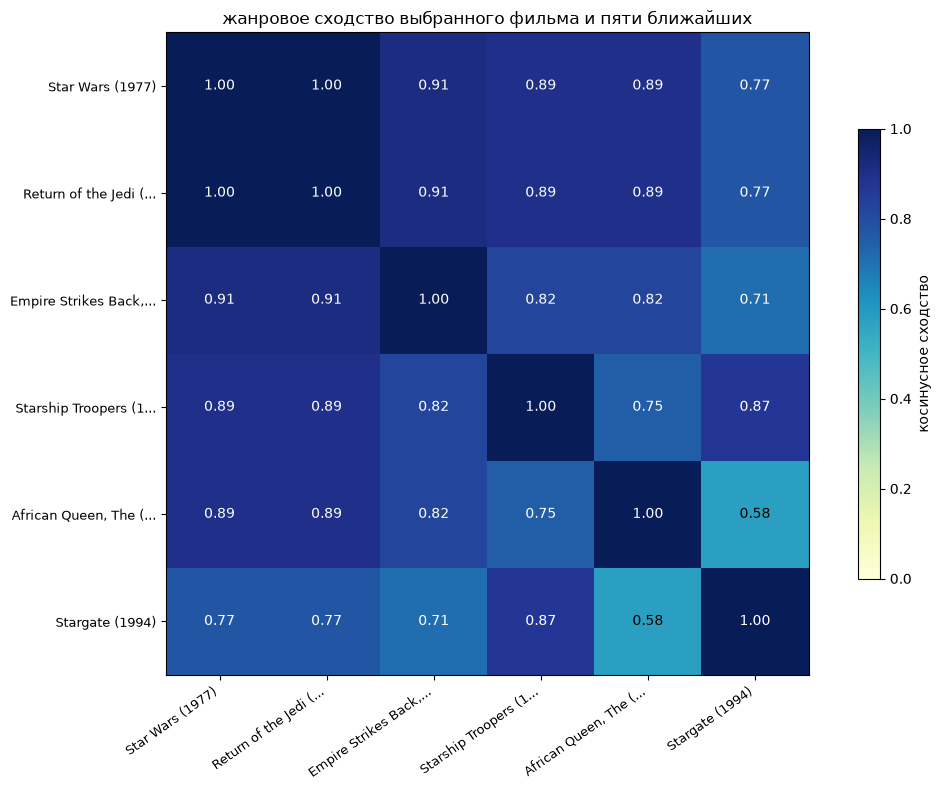

In [9]:
heat_ids = [MOVIE_ID] + similar_top10.index[:5].tolist()
heat = content_similarity.loc[heat_ids, heat_ids]
labels = [
    (t if len(t := catalog.loc[i, "title"]) <= 23 else t[:20] + "...")
    for i in heat_ids
]

fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(heat, vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(range(6), labels=labels, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(6), labels=labels, fontsize=9)

for i in range(6):
    for j in range(6):
        value = heat.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if value >= 0.65 else "black")
        
ax.set_title("жанровое сходство выбранного фильма и пяти ближайших")
fig.colorbar(im, ax=ax, label="косинусное сходство", shrink=0.7)
plt.tight_layout()
plt.show()

Ближе всего к Star Wars оказался Return of the Jedi: у них в каталоге одинаковые 5 жанров, так что сходство равно 1. Вообще можно сказать, что это один и тот же фильм, а на деле - продолжение. Так что по смыслу и жанру это одно и то же, только продолжение. Думаю, что все части индианы джонса имели бы схожу картину. У The Empire Strikes Back дополнительно указан Drama, и сходство немного ниже - около 0,913. В топ попали также Starship Troopers и The African Queen, у которых совпала большая часть жанров

жанры описывают фильм довольно грубо. Например, The African Queen попадает в список рядом с космической фантастикой по сочетанию Action, Adventure, Romance и War. Отношение зрителей актеры и сюжет не учитываются в таком сравнении

### 3. Content-Based Filtering: персонализированные рекомендации

Беру пользователя 303, как в первой лабораторной, потому что он оценил больше всех фильмов и теперь это будет традиция
. Профиль считаю по формуле из задания:

$$p_u=\frac{\sum_{i\in I_u}w_{ui}x_i}{\sum_{i\in I_u}w_{ui}},\qquad w_{ui}=\max(r_{ui}-3,0).$$

Оценка 5 даёт вес 2, оценка 4 - вес 1, остальные - вес 0. Значение жанра в профиле показывает, какая доля положительного веса приходится на фильмы этого жанра. Сумма значений может быть больше единицы, потому что у фильма бывает несколько жанров.

In [10]:
USER_ID = 303
k = 5
MIN_COMMON = 3
user_ratings = user_item.loc[USER_ID].dropna()
weights = (user_ratings - 3).clip(lower=0)

seen_ids = user_ratings.index
unseen_ids = catalog.index[~catalog.index.isin(seen_ids)]
profile = genre_features.loc[seen_ids].mul(weights, axis=0).sum(axis=0) / weights.sum()
profile_top3 = profile.sort_values(ascending=False, kind="stable").head(3)

print("пользователь:", USER_ID)
print("оценённых фильмов:", len(user_ratings))
print("положительных оценок:", int((user_ratings >= 4).sum()))
print("ещё не оценённых фильмов:", len(unseen_ids))
print("три ведущих жанра:")

profile_top3.rename("вес в профиле").to_frame()



пользователь: 303
оценённых фильмов: 484
положительных оценок: 251
ещё не оценённых фильмов: 619
три ведущих жанра:


,вес в профиле
Comedy,0.398844
Drama,0.384393
Romance,0.216763


этот пользователь по профилю на меня похож

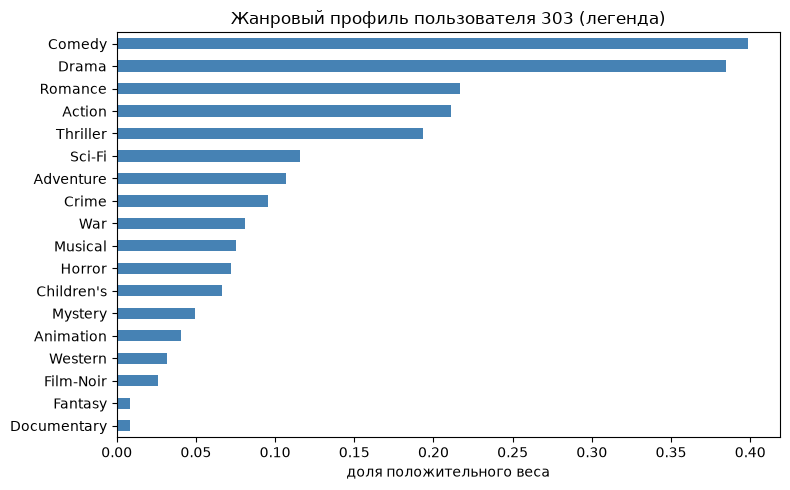

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
profile.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("доля положительного веса")
ax.set_title(f"Жанровый профиль пользователя {USER_ID} (легенда)")
plt.tight_layout()
plt.show()

In [12]:
profile_norm = np.linalg.norm(profile.to_numpy())

content_scores = pd.Series(
    X_normalized @ (profile.to_numpy() / profile_norm),
    index=catalog.index, name="score"
).clip(0, 1)

content_candidates = (
    content_scores.loc[unseen_ids].round(12).reset_index()
    .sort_values(["score", "movie_id"], ascending=[False, True])
)
content_top5 = content_candidates.head(5).set_index("movie_id").join(catalog[["title", "genres"]])
print("доступных кандидатов:", len(content_candidates))

content_top5[["title", "genres", "score"]].round(4)

доступных кандидатов: 619


,title,genres,score
movie_id,,,
512,Wings of Desire (1987),"Comedy, Drama, Romance",0.8186
731,"Corrina, Corrina (1994)","Comedy, Drama, Romance",0.8186
936,Brassed Off (1996),"Comedy, Drama, Romance",0.8186
1115,Twelfth Night (1996),"Comedy, Drama, Romance",0.8186
337,"House of Yes, The (1997)","Comedy, Drama, Thriller",0.7997


Пользователь 303 оценил 484 фильма, из них 251 получил 4 или 5. В профиле больше всего веса у Comedy (0,399), Drama (0,384) и Romance (0,217). Поэтому первые четыре рекомендации имеют одинаковый набор Comedy, Drama, Romance и одинаковый score около 0,819. Пятая - The House of Yes с жанрами Comedy, Drama, Thriller.

история здесь влияет через положительные оценки: пятёрка усиливает жанры вдвое сильнее четвёрки. При этом оценки 1-3 не уменьшают интерес к жанру, а просто не добавляют веса. Метод повторяет знакомые сочетания жанров, поэтому разнообразие получается ограниченным. Высокий score означает сходство с профилем, а не прогноз оценки по шкале от 1 до 5.

### 4. User-Based Collaborative Filtering

Сравниваю пользователя 303 с остальными по фильмам, которые оценили оба. Если общих фильмов меньше трёх, пару исключаю.

$$sim(u,v)=\frac{\sum_{i\in I_{uv}}r_{ui}r_{vi}}{\sqrt{\sum_{i\in I_{uv}}r_{ui}^2}\sqrt{\sum_{i\in I_{uv}}r_{vi}^2}}.$$

В знаменателе тоже беру только общие фильмы. Ниже функция считает такое сходство для каждой пары строк. Нули в её промежуточных массивах нужны для умножения матриц, они не превращают пропуски в реальные оценки.

In [13]:
def shared_cosine(ratings, min_common=3):
    """<>"""
    values = np.nan_to_num(ratings.to_numpy(dtype=float), nan=0.0)
    known = ratings.notna().to_numpy(dtype=float)
    common = known @ known.T
    products = values @ values.T

    # Для пары строк суммируем квадраты только в общих столбцах.
    squares = (values ** 2) @ known.T
    denominator = np.sqrt(squares * squares.T)
    similarity = np.full(products.shape, np.nan)
    np.divide(products, denominator, out=similarity,
              where=(common >= min_common) & (denominator > 0))
    similarity = np.clip(similarity, 0, 1)
    np.fill_diagonal(similarity, np.nan)
    return (
        pd.DataFrame(similarity, index=ratings.index, columns=ratings.index),
        pd.DataFrame(common.astype(int), index=ratings.index, columns=ratings.index)
    )


In [14]:

user_similarity, user_common = shared_cosine(user_item, MIN_COMMON)

neighbor_candidates = pd.DataFrame({
    "similarity": user_similarity.loc[USER_ID],
    "common_movies": user_common.loc[USER_ID]
}).drop(index=USER_ID).dropna(subset=["similarity"])

neighbors = (
    neighbor_candidates.reset_index()
    .assign(similarity=lambda t: t["similarity"].round(12))
    .sort_values(["similarity", "user_id"], ascending=[False, True])
    .head(k).set_index("user_id")
)


print("кандидатов в соседи:", len(neighbor_candidates))
print("выбрано соседей:", len(neighbors))
display(neighbors.round(4))



кандидатов в соседи: 62
выбрано соседей: 5


,similarity,common_movies
user_id,,
10,0.9861,108
118,0.9841,51
785,0.9816,21
132,0.9799,11
694,0.9789,78


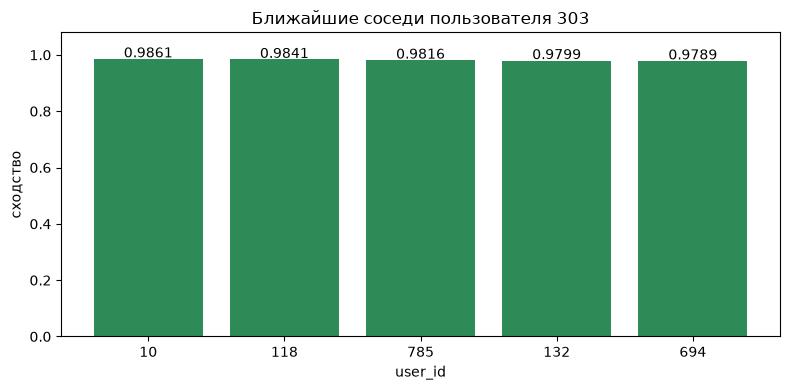

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(neighbors.index.astype(str), neighbors["similarity"], color="seagreen")
for i, (uid, row) in enumerate(neighbors.iterrows()):
    ax.text(i, row["similarity"] + 0.005, f'{row["similarity"]:.4f}', ha="center")
ax.set_ylim(0, 1.08)
ax.set_xlabel("user_id")
ax.set_ylabel("сходство")
ax.set_title(f"Ближайшие соседи пользователя {USER_ID}")
plt.tight_layout()
plt.show()

Из найденных пяти соседей для каждого фильма беру только тех, кто его оценил:

$$\hat r_{ui}=\frac{\sum_{v\in N_i(u)}sim(u,v)r_{vi}}{\sum_{v\in N_i(u)}|sim(u,v)|}.$$

Если оценок выбранных соседей нет, прогноз оставляю неизвестным. Для всех алгоритмов равные итоговые значения упорядочиваю по movie_id.

In [16]:
neighbor_ratings = user_item.loc[neighbors.index, unseen_ids]
neighbor_weights = user_similarity.loc[USER_ID, neighbors.index]
user_numerator = neighbor_ratings.mul(neighbor_weights, axis=0).sum(axis=0)
user_denominator = neighbor_ratings.notna().mul(neighbor_weights.abs(), axis=0).sum(axis=0)
user_predictions = user_numerator.div(user_denominator.where(user_denominator > 0))


In [17]:
user_candidates = pd.DataFrame({
    "prediction": user_predictions,
    "neighbors_used": neighbor_ratings.notna().sum(axis=0)
}).dropna(subset=["prediction"])
user_candidates["prediction"] = user_candidates["prediction"].round(12)
user_candidates = user_candidates.reset_index().sort_values(
    ["prediction", "movie_id"], ascending=[False, True]
)
user_top5 = user_candidates.head(5).set_index("movie_id").join(catalog[["title", "genres"]])

In [18]:
print("доступных кандидатов:", len(user_candidates))
print("фильмов без прогноза:", int(user_predictions.isna().sum()))
if len(user_top5) < 5:
    print("Рекомендаций меньше пяти: выбранные соседи оценили недостаточно новых фильмов.")
display(user_top5[["title", "genres", "prediction", "neighbors_used"]].round(4))

доступных кандидатов: 143
фильмов без прогноза: 476


,title,genres,prediction,neighbors_used
movie_id,,,,
131,Breakfast at Tiffany's (1961),"Drama, Romance",5.0,1
133,Gone with the Wind (1939),"Drama, Romance, War",5.0,2
135,2001: A Space Odyssey (1968),"Drama, Mystery, Sci-Fi, Thriller",5.0,3
177,"Good, The Bad and The Ugly, The (1966)","Action, Western",5.0,1
188,Full Metal Jacket (1987),"Action, Drama, War",5.0,2


Ближайшие соседи - пользователи 10, 118, 785, 132 и 694. Сходство получилось от 0,979 до 0,986, число общих фильмов - от 11 до 108. Их оценки на общих фильмах близки по направлению вектора. Косинус без вычитания средней может быть высоким и у людей с разной строгостью оценивания, поэтому нельзя удтверждать о совпадении вкусов

У всех пяти рекомендаций прогноз равен 5: выбранные соседи, оценившие эти фильмы, поставили им пятёрки. Но опора разная: у Breakfast at Tiffany's и The Good, the Bad and the Ugly есть только одна оценка выбранного соседа, а у 2001: A Space Odyssey - три. Такой прогноз по одной оценке менее надёжен.

Прогноз удалось получить для 143 из 619 новых для пользователя фильмов. Для остальных 476 ни один из выбранных пяти соседей не оставил оценку

### 5. Item-Based Collaborative Filtering

Теперь сравниваю фильмы по оценкам общих пользователей. Жанры в расчёте не участвуют. У пары фильмов должно быть хотя бы три общих пользователя

$$sim(i,j)=\frac{\sum_{u\in U_{ij}}r_{ui}r_{uj}}{\sqrt{\sum_{u\in U_{ij}}r_{ui}^2}\sqrt{\sum_{u\in U_{ij}}r_{uj}^2}}.$$

Для каждого нового фильма выбираю до пяти наиболее похожих фильмов, которые пользователь 303 уже оценивал:

$$\hat r_{ui}=\frac{\sum_{j\in N_u(i)}sim(i,j)r_{uj}}{\sum_{j\in N_u(i)}|sim(i,j)|}$$

Если подходящих фильмов из истории нет, прогноз не рассчитываю

In [23]:
item_similarity, item_common = shared_cosine(user_item.T, MIN_COMMON)
item_rows = []
item_neighbors = {}

for movie_id in unseen_ids:
    nearest = (
        item_similarity.loc[movie_id, seen_ids].dropna().rename("similarity")
        .round(12).reset_index()
        .sort_values(["similarity", "movie_id"], ascending=[False, True])
        .head(k).set_index("movie_id")["similarity"]
    )
    if nearest.empty or nearest.abs().sum() == 0:
        continue
    prediction = (nearest * user_ratings.loc[nearest.index]).sum() / nearest.abs().sum()
    item_rows.append({
        "movie_id": movie_id,
        "prediction": round(float(prediction), 12),
        "neighbors_used": len(nearest)
    })
    item_neighbors[movie_id] = nearest

item_candidates = pd.DataFrame(item_rows, columns=["movie_id", "prediction", "neighbors_used"])
item_candidates = item_candidates.sort_values(
    ["prediction", "movie_id"], ascending=[False, True]
)
item_top5 = item_candidates.head(5).set_index("movie_id").join(catalog[["title", "genres"]])
print("размер матрицы сходства фильмов:", item_similarity.shape)
print("доступных кандидатов:", len(item_candidates))
print("фильмов без прогноза:", len(unseen_ids) - len(item_candidates))


item_top5[["title", "genres", "prediction", "neighbors_used"]]

размер матрицы сходства фильмов: (1103, 1103)
доступных кандидатов: 301
фильмов без прогноза: 318


,title,genres,prediction,neighbors_used
movie_id,,,,
114,Wallace & Gromit: The Best of Aardman Animatio...,Animation,5.0,5
131,Breakfast at Tiffany's (1961),"Drama, Romance",5.0,5
311,"Wings of the Dove, The (1997)","Drama, Romance, Thriller",5.0,1
316,As Good As It Gets (1997),"Comedy, Drama",5.0,5
317,In the Name of the Father (1993),Drama,5.0,5


объясняю рекомендацию: Wallace & Gromit: The Best of Aardman Animation (1996)
всего соседей в прогнозе 5
три наиболее похожих фильма из истории:

In [26]:
explained_id = item_top5.index[0]
nearest = item_neighbors[explained_id]
explanation = nearest.rename("similarity").to_frame()
explanation["user_rating"] = user_ratings.loc[nearest.index]
explanation["common_users"] = item_common.loc[explained_id, nearest.index]
explanation["contribution"] = (
    explanation["similarity"] * explanation["user_rating"] / nearest.abs().sum()
)
explanation = explanation.join(catalog[["title", "genres"]])

In [24]:
explanation.head(3)[
    ["title", "genres", "user_rating", "similarity", "common_users", "contribution"]
]

,title,genres,user_rating,similarity,common_users,contribution
movie_id,,,,,,
172,"Empire Strikes Back, The (1980)","Action, Adventure, Drama, Romance, Sci-Fi, War",5.0,1.0,3,1.002029
173,"Princess Bride, The (1987)","Action, Adventure, Comedy, Romance",5.0,1.0,3,1.002029
181,Return of the Jedi (1983),"Action, Adventure, Romance, Sci-Fi, War",5.0,1.0,3,1.002029


сумма вкладов всех соседей 5
прогноз 5

Для пользователя 303 нашлись прогнозы по 301 фильму. Ещё 318 фильмов остались без прогноза: в истории пользователя нет соседей с нужными тремя общими оценившими пользователями.

У первой рекомендации, Wallace & Gromit: The Best of Aardman Animation, прогноз равен 5. В расчёт вошли пять фильмов из истории, и всем им пользователь поставил пятёрки. Первые три соседа - The Empire Strikes Back, The Princess Bride и Return of the Jedi. Для каждой из этих пар есть только три общих пользователя, а сходство равно 1. Это точное совпадение направления оценок на маленьком пересечении, поэтому относиться к нему стоит осторожно.

Сам рекомендованный фильм имеет жанр Animation, а среди его соседей есть фантастика, приключения и комедия. Здесь сходство определяется оценками общих пользователей, поэтому оно может быть высоким и у фильмов разных жанров. В жанровом сравнении из задания 2 такие фильмы не обязательно оказались бы рядом.

В топе есть и Wings of the Dove, для которого нашёлся только один подходящий сосед. По условию можно использовать до пяти, поэтому прогноз рассчитан, но его поддержка слабее.

### 6. Сравнение рекомендательных алгоритмов

Popularity-Based повторяю из первой работы: минимум пять оценок, сортировка сначала по их количеству, потом по средней оценке. Фильмы из истории пользователя исключаю. В этой таблице сравниваю именно популярность, без байесовского сглаживания

У всех четырёх методов один пользователь и один каталог. Число доступных кандидатов считаю после исключения уже оценённых фильмов и применения условий конкретного метода

In [27]:
popularity_stats = df.groupby("movie_id")["rating"].agg(count="count", mean="mean")
popularity_candidates = (
    popularity_stats.loc[~popularity_stats.index.isin(seen_ids)]
    .query("count >= 5").reset_index()
    .sort_values(["count", "mean", "movie_id"], ascending=[False, False, True])
)
popularity_top5 = popularity_candidates.head(5).set_index("movie_id").join(catalog[["title", "genres"]])

recommendations = {
    "Popularity-Based": popularity_top5,
    "Content-Based": content_top5,
    "User-Based CF": user_top5,
    "Item-Based CF": item_top5
}



In [35]:
for name, table in recommendations.items():
    print(name)
    cols = {
        "Popularity-Based": ["title", "genres", "count", "mean"],
        "Content-Based": ["title", "genres", "score"],
        "User-Based CF": ["title", "genres", "prediction", "neighbors_used"],
        "Item-Based CF": ["title", "genres", "prediction", "neighbors_used"]
    }[name]
    display(table[cols].round(4))

principles = ["Популярность", "Жанровый профиль", "Похожие пользователи", "Похожие фильмы по оценкам"]
candidate_counts = [
    len(popularity_candidates), len(content_candidates),
    len(user_candidates), len(item_candidates)
]

comparison = pd.DataFrame({
    "Алгоритм": list(recommendations),
    "Принцип построения": principles,
    "Top-5 фильмов": ["; ".join(t["title"]) for t in recommendations.values()],
    "Количество доступных кандидатов": candidate_counts
})


Popularity-Based


,title,genres,count,mean
movie_id,,,,
275,Sense and Sensibility (1995),"Drama, Romance",21,3.7619
471,Courage Under Fire (1996),"Drama, War",20,3.7000
265,"Hunt for Red October, The (1990)","Action, Thriller",18,3.8889
322,Murder at 1600 (1997),"Mystery, Thriller",18,3.2222
313,Titanic (1997),"Action, Drama, Romance",17,4.4118


Content-Based


,title,genres,score
movie_id,,,
512,Wings of Desire (1987),"Comedy, Drama, Romance",0.8186
731,"Corrina, Corrina (1994)","Comedy, Drama, Romance",0.8186
936,Brassed Off (1996),"Comedy, Drama, Romance",0.8186
1115,Twelfth Night (1996),"Comedy, Drama, Romance",0.8186
337,"House of Yes, The (1997)","Comedy, Drama, Thriller",0.7997


User-Based CF


,title,genres,prediction,neighbors_used
movie_id,,,,
131,Breakfast at Tiffany's (1961),"Drama, Romance",5.0,1
133,Gone with the Wind (1939),"Drama, Romance, War",5.0,2
135,2001: A Space Odyssey (1968),"Drama, Mystery, Sci-Fi, Thriller",5.0,3
177,"Good, The Bad and The Ugly, The (1966)","Action, Western",5.0,1
188,Full Metal Jacket (1987),"Action, Drama, War",5.0,2


Item-Based CF


,title,genres,prediction,neighbors_used
movie_id,,,,
114,Wallace & Gromit: The Best of Aardman Animatio...,Animation,5.0,5
131,Breakfast at Tiffany's (1961),"Drama, Romance",5.0,5
311,"Wings of the Dove, The (1997)","Drama, Romance, Thriller",5.0,1
316,As Good As It Gets (1997),"Comedy, Drama",5.0,5
317,In the Name of the Father (1993),Drama,5.0,5


In [33]:
from IPython.display import HTML, display

html = comparison.to_html(index=False).replace(
    "<td>", '<td style="white-space:normal;max-width:420px;padding:8px">'
)
display(HTML(html))

Алгоритм,Принцип построения,Top-5 фильмов,Количество доступных кандидатов
Popularity-Based,Популярность,"Sense and Sensibility (1995); Courage Under Fire (1996); Hunt for Red October, The (1990); Murder at 1600 (1997); Titanic (1997)",159
Content-Based,Жанровый профиль,"Wings of Desire (1987); Corrina, Corrina (1994); Brassed Off (1996); Twelfth Night (1996); House of Yes, The (1997)",619
User-Based CF,Похожие пользователи,"Breakfast at Tiffany's (1961); Gone with the Wind (1939); 2001: A Space Odyssey (1968); Good, The Bad and The Ugly, The (1966); Full Metal Jacket (1987)",143
Item-Based CF,Похожие фильмы по оценкам,"Wallace & Gromit: The Best of Aardman Animation (1996); Breakfast at Tiffany's (1961); Wings of the Dove, The (1997); As Good As It Gets (1997); In the Name of the Father (1993)",301


In [39]:
names = list(recommendations)
overlap = pd.DataFrame(0, index=names, columns=names)
for left in names:
    for right in names:
        overlap.loc[left, right] = len(
            set(recommendations[left].index) & set(recommendations[right].index)
        )
        
print("Количество общих фильмов в топах:")
display(overlap)
print("На диагонали - размер собственного списка, остальные клетки показывают пересечения")

Количество общих фильмов в топах:


,Popularity-Based,Content-Based,User-Based CF,Item-Based CF
Popularity-Based,5,0,0,0
Content-Based,0,5,0,0
User-Based CF,0,0,5,1
Item-Based CF,0,0,1,5


На диагонали - размер собственного списка, остальные клетки показывают пересечения


У Content-Based больше всего доступных кандидатов - 619, то есть все ещё не оценённые фильмы своего каталога. Нулевой жанровый вектор даёт score 0 и не позволяет судить о сходстве. У популярности после порога в пять оценок остаётся 159 кандидатов, у User-Based - 143, у Item-Based - 301

Популярность дала тот же топ, что и в первой - Sense and Sensibility, Courage Under Fire, The Hunt for Red October, Murder at 1600 и Titanic. С контентным топом и CF-топами совпадений нет. User-Based и Item-Based совпали на одном фильме - Breakfast at Tiffany's. Все остальные попарные пересечения равны нулю

разницу я бы объяснил исходными данными методов: популярность смотрит на общий спрос, контентный метод - на жанры положительно оценённых фильмов, а CF - на связи в оценках

### 7. Выводы по лабораторной работе

В работе я продолжил исследование 8 варианта и построил три персонализированных метода для пользователя любимого пользователя 303. Данные разрежены на ~90%, поэтому ограничения по общим оценкам заметно сокращают число прогнозов

Жанровый профиль выделил Comedy, Drama и Romance (мои жанры). Контентные рекомендации повторяют эти сочетания, но не различают фильмы с одинаковыми жанрами. User-Based использовал оценки пяти похожих пользователей и смог оценить 143 кандидата. Item-Based сравнивал фильмы по общим пользователям и дал прогнозы для 301 кандидата.

Высокий прогноз не всегда означает надёжную рекомендацию - часть пятёрок получена по одному соседу, а сходство фильмов иногда рассчитано всего по трём пользователям. Так что вместе с прогнозами я вывел число соседей, а для одной Item-Based рекомендации разобрал вклад фильмов из истории.

У двух CF-методов совпал один фильм в топ-5, остальные списки различаются. Каждый метод использует свою информацию, и выбор между ними требует отдельной проверки качества на отложенных данных.

### Контрольные вопросы
1.	Что такое персонализированная рекомендательная система?
2.	В чём заключается принцип Content-Based Filtering?
3.	Как формируется вектор признаков фильма?
4.	Что представляет собой пользовательский профиль в контентной фильтрации?
5.	В чём заключается основная идея Collaborative Filtering?
6.	Чем User-Based CF отличается от Item-Based CF?
7.	Для чего используется алгоритм KNN?
8.	Как значение K влияет на качество рекомендаций?
9.	Почему сходство пользователей желательно рассчитывать по общим оценённым объектам?
10.	Как прогнозируется пользовательская оценка в User-Based CF?
11.	Почему контентный и коллаборативный алгоритмы могут предлагать разные фильмы?
12.	Как можно решить проблему отсутствия подходящих соседей?

### Ответы на контрольные вопросы

**1. Что такое персонализированная рекомендательная система?**

Это система, которая подбирает объекты под конкретного пользователя по его оценкам, действиям или предпочтениям. В этой работе рекомендации зависят от истории пользователя 303.

**2. В чём заключается принцип Content-Based Filtering?**

Система сравнивает признаки объектов с интересами пользователя. Здесь признаки - жанры фильмов, а интересы я получаю из положительных оценок.

**3. Как формируется вектор признаков фильма?**

Каждому жанру соответствует отдельный столбец. Если фильм относится к жанру, записываю 1, иначе 0. У одного фильма может быть несколько единиц.

**4. Что представляет собой пользовательский профиль в контентной фильтрации?**

Это средневзвешенный вектор признаков оценённых фильмов. В задании вес равен max(rating - 3, 0), поэтому пятёрки влияют сильнее четвёрок, а оценки от 1 до 3 не добавляют веса.

**5. В чём заключается основная идея Collaborative Filtering?**

Рекомендации строятся по пользовательским оценкам. Если люди похожим образом оценивают общие фильмы, их оценки можно использовать для подбора новых фильмов друг другу.

**6. Чем User-Based CF отличается от Item-Based CF?**

User-Based ищет похожих пользователей и использует их оценки нового фильма. Item-Based ищет похожие фильмы из истории целевого пользователя и использует его собственные оценки этих фильмов.

**7. Для чего используется алгоритм KNN?**

Он выбирает K ближайших соседей по заданной мере сходства. В User-Based соседями являются пользователи, в Item-Based - фильмы. Здесь K = 5.

**8. Как значение K влияет на качество рекомендаций?**

При малом K прогноз сильно зависит от отдельных соседей. При большем K оценок обычно хватает для большего числа кандидатов, но в расчёт могут попасть менее похожие соседи. Подбирать K лучше по качеству на отложенных данных.

**9. Почему сходство пользователей желательно рассчитывать по общим оценённым объектам?**

Только на общих фильмах можно напрямую сравнить их оценки. Пропуск не говорит об отношении к фильму. В работе общие объекты используются и в числителе, и в знаменателе косинуса, а пары с менее чем тремя общими оценками исключаются.

**10. Как прогнозируется пользовательская оценка в User-Based CF?**

Беру взвешенное среднее оценок выбранных соседей, которые оценили нужный фильм. Весом служит сходство с целевым пользователем. Если таких соседей нет, прогноз не рассчитывается.

**11. Почему контентный и коллаборативный алгоритмы могут предлагать разные фильмы?**

Они используют разные данные. Контентный метод опирается на жанры, а коллаборативный - на оценки. Два фильма разных жанров могут получать похожие оценки, а фильмы одного жанра могут нравиться разным людям.

**12. Как можно решить проблему отсутствия подходящих соседей?**

Можно собрать больше оценок, расширить выборку пользователей или использовать контентные рекомендации и популярность как запасной вариант. Изменение K или порога общих оценок тоже меняет число кандидатов, но может снизить надёжность сходства. В этой работе пороги из задания сохраняю, а недоступные прогнозы пропускаю.